# TP 4 · Architecture Transformer

Ce notebook étudie trois usages des modèles séquentiels : prévoir une mesure, prolonger un texte et retrouver un mot masqué.

- **Première partie** — comparaison RNN, LSTM et Transformer sur une sinusoïde, puis essais de deux modèles de langage préentraînés.
- **Deuxième partie** — prévision de puissance électrique, entraînement d’un mini-GPT et entraînement d’un mini-BERT.

**Exécution.** Décompresser le dossier, installer les dépendances avec `python -m pip install -r requirements.txt`, puis ouvrir ce notebook dans Jupyter et exécuter toutes les cellules dans l’ordre. Garder `corpus.txt` et l’archive des mesures dans le dossier du notebook. Les modèles préentraînés sont téléchargés au premier lancement.

In [1]:
from copy import deepcopy
from pathlib import Path
from zipfile import ZipFile
import itertools
import os
import re

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset

GRAINE = 27
torch.manual_seed(GRAINE)
torch.set_num_threads(min(4, os.cpu_count() or 1))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 110
BLEU, VERT, ORANGE = "#254F80", "#167D73", "#C16A31"
print(f"PyTorch {torch.__version__} · Calcul sur {device}")

PyTorch 2.15.0+cpu · Calcul sur cpu


## Première partie · Prévoir la suite d’une sinusoïde

On échantillonne $y=\sin(x)$ en **200 points entre 0 et 20**. Chaque fenêtre de **10 observations** a pour cible l’observation immédiatement suivante. La répartition 70/15/15 est chronologique, avec des contextes d’évaluation composés de mesures déjà connues à l’heure de la prédiction. Les trois modèles voient les mêmes données.

Fenêtres et cibles : torch.Size([190, 10, 1]) torch.Size([190, 1])
Répartition : {'train': 133, 'validation': 28, 'test': 29}
Première fenêtre : [0.    0.1   0.2   0.297 0.391 0.482 0.567 0.647 0.72  0.786] ; cible : 0.844


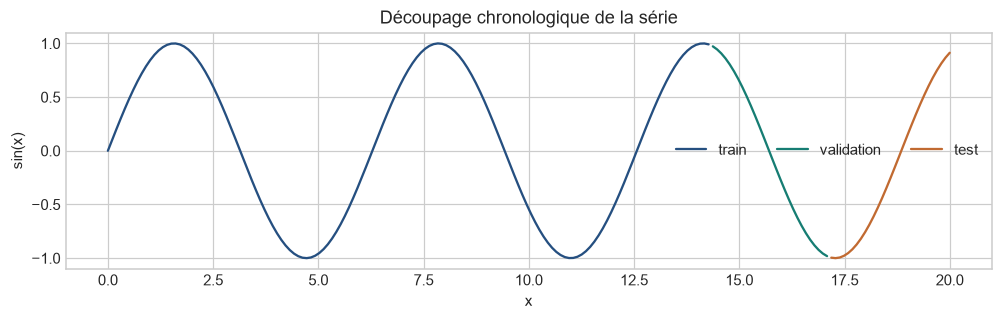

In [2]:
def fenetres(serie, largeur):
    blocs = np.lib.stride_tricks.sliding_window_view(serie, largeur + 1)
    indices = np.arange(largeur, len(serie))
    valides = np.isfinite(blocs).all(axis=1)
    blocs = blocs[valides].astype(np.float32)
    return torch.from_numpy(blocs[:, :-1, None]), torch.from_numpy(blocs[:, -1:]), indices[valides]

def decouper(indices, fin_train, fin_val):
    return {
        "train": indices < fin_train,
        "validation": (indices >= fin_train) & (indices < fin_val),
        "test": indices >= fin_val,
    }

def chargeurs(entrees, cibles, groupes, taille):
    return {
        nom: DataLoader(
            TensorDataset(entrees[masque], cibles[masque]),
            batch_size=taille,
            shuffle=(nom == "train"),
            generator=torch.Generator().manual_seed(GRAINE),
        )
        for nom, masque in groupes.items()
    }

abscisse = np.linspace(0, 20, 200)
sinus = np.sin(abscisse)
x_sin, y_sin, i_sin = fenetres(sinus, 10)
g_sin = decouper(i_sin, 143, 171)
assert x_sin.shape == (190, 10, 1) and y_sin.shape == (190, 1)
print("Fenêtres et cibles :", x_sin.shape, y_sin.shape)
print("Répartition :", {nom: int(masque.sum()) for nom, masque in g_sin.items()})
print(f"Première fenêtre : {x_sin[0, :, 0].numpy().round(3)} ; cible : {y_sin[0, 0]:.3f}")

fig, ax = plt.subplots(figsize=(9, 2.8), layout="constrained")
for nom, bornes, couleur in zip(g_sin, [slice(0, 143), slice(143, 171), slice(171, None)], [BLEU, VERT, ORANGE]):
    ax.plot(abscisse[bornes], sinus[bornes], color=couleur, label=nom)
ax.set(xlabel="x", ylabel="sin(x)", title="Découpage chronologique de la série")
ax.legend(ncol=3)
plt.show()

### RNN, LSTM et encodeur Transformer

Le RNN et le LSTM utilisent 16 unités et transmettent le dernier état caché à une couche linéaire. Le LSTM utilise aussi un état de cellule et des portes qui contrôlent la circulation de l’information. Le Transformer projette chaque mesure de 1 à 16 dimensions, ajoute un embedding de position, puis applique un bloc à deux têtes avec un réseau interne 16 → 32 → 16. La régression utilise la dernière représentation. L’attention porte sur les dix observations disponibles et la cible reste hors de l’entrée.

In [3]:
class RegresseurRecurrent(nn.Module):
    def __init__(self, cellule):
        super().__init__()
        self.recurrence = cellule(input_size=1, hidden_size=16, batch_first=True)
        self.sortie = nn.Linear(16, 1)

    def forward(self, mesures):
        etats, _ = self.recurrence(mesures)
        return self.sortie(etats[:, -1])


class TransformerSerie(nn.Module):
    def __init__(self, largeur, dimension, tetes, dimension_mlp, couches, dropout):
        super().__init__()
        self.projection = nn.Linear(1, dimension)
        self.position = nn.Embedding(largeur, dimension)
        couche = nn.TransformerEncoderLayer(
            d_model=dimension, nhead=tetes, dim_feedforward=dimension_mlp,
            dropout=dropout, batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, couches, enable_nested_tensor=False)
        self.sortie = nn.Linear(dimension, 1)

    def forward(self, mesures):
        positions = torch.arange(mesures.size(1), device=mesures.device)
        representations = self.projection(mesures) + self.position(positions)
        return self.sortie(self.encodeur(representations)[:, -1])


def entrainer_regression(modele, lots, epoques, lr, patience=None, journal=None):
    modele.to(device)
    optim = torch.optim.Adam(modele.parameters(), lr=lr)
    historique = []
    minimum, meilleure_epoque = float("inf"), 0
    for epoque in range(1, epoques + 1):
        modele.train()
        cumul = 0.0
        for x, y in lots["train"]:
            x, y = x.to(device), y.to(device)
            optim.zero_grad(set_to_none=True)
            perte = F.mse_loss(modele(x), y)
            perte.backward()
            optim.step()
            cumul += perte.item() * len(x)
        pred, vrai = predire_regression(modele, lots["validation"])
        validation = np.mean((pred - vrai) ** 2).item()
        historique.append((cumul / len(lots["train"].dataset), validation))
        if validation < minimum:
            minimum, meilleure_epoque = validation, epoque
            poids = deepcopy(modele.state_dict())
        if journal and (epoque == 1 or epoque % journal == 0):
            print(f"Époque {epoque:2d} · MSE validation {validation:.4f}", flush=True)
        if patience and epoque - meilleure_epoque >= patience:
            break
    modele.load_state_dict(poids)
    return pd.DataFrame(historique, columns=["Train", "Validation"],
                        index=pd.RangeIndex(1, len(historique) + 1, name="Époque")), meilleure_epoque


@torch.inference_mode()
def predire_regression(modele, lot):
    modele.eval()
    predictions, observations = [], []
    for x, y in lot:
        predictions.append(modele(x.to(device)).cpu())
        observations.append(y)
    return torch.cat(predictions).flatten().numpy(), torch.cat(observations).flatten().numpy()


def erreurs(pred, vrai):
    residus = pred - vrai
    return {"MAE": np.abs(residus).mean(), "RMSE": np.sqrt(np.mean(residus ** 2))}

,MAE,RMSE,MSE,Paramètres,Époque retenue
RNN,0.006684,0.007673,0.000059,321,227
LSTM,0.003121,0.003497,0.000012,1233,230
Transformer,0.001729,0.002055,0.000004,2433,233
Persistance,0.066604,0.073248,0.005365,0,—


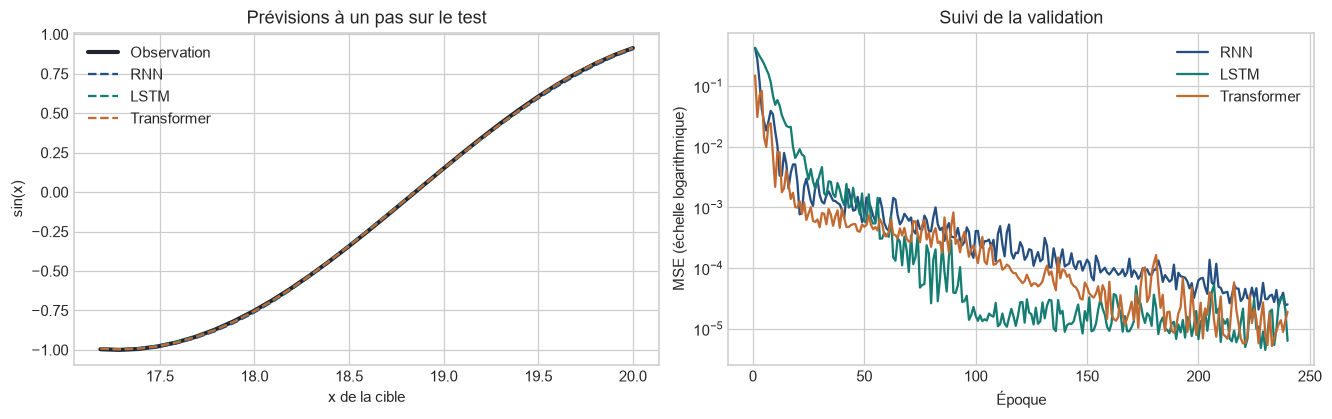

Sur ce test, Transformer obtient la plus faible RMSE parmi les modèles entraînés (0.00205).
Exemple de cible : -0.99569. Prévisions : RNN = -0.99138, LSTM = -0.99290, Transformer = -0.99144


In [4]:
modeles = {
    "RNN": RegresseurRecurrent(nn.RNN),
    "LSTM": RegresseurRecurrent(nn.LSTM),
    "Transformer": TransformerSerie(10, 16, 2, 32, 1, 0.0),
}
predictions_sin, historique_sin, resultats = {}, {}, {}
for nom, modele in modeles.items():
    lots = chargeurs(x_sin, y_sin, g_sin, taille=64)
    historique_sin[nom], epoque = entrainer_regression(modele, lots, 240, 0.005)
    pred, vrai = predire_regression(modele, lots["test"])
    predictions_sin[nom] = pred
    resultats[nom] = {
        **erreurs(pred, vrai), "MSE": np.mean((pred - vrai) ** 2),
        "Paramètres": sum(p.numel() for p in modele.parameters()),
        "Époque retenue": epoque,
    }
resultats["Persistance"] = {
    **erreurs(x_sin[g_sin["test"], -1, 0].numpy(), vrai),
    "MSE": np.mean((x_sin[g_sin["test"], -1, 0].numpy() - vrai) ** 2),
    "Paramètres": 0,
}
table_sin = pd.DataFrame.from_dict(resultats, orient="index")
display(table_sin.style.format(precision=6, subset=["MAE", "RMSE", "MSE"])
        .format(precision=0, subset=["Époque retenue"], na_rep="—"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.7), layout="constrained")
abscisse_test = abscisse[i_sin[g_sin["test"]]]
axes[0].plot(abscisse_test, vrai, color="#202631", linewidth=2.7, label="Observation")
for (nom, pred), couleur in zip(predictions_sin.items(), [BLEU, VERT, ORANGE]):
    axes[0].plot(abscisse_test, pred, "--", color=couleur, label=nom)
    axes[1].semilogy(historique_sin[nom]["Validation"], color=couleur, label=nom)
axes[0].set(xlabel="x de la cible", ylabel="sin(x)", title="Prévisions à un pas sur le test")
axes[1].set(xlabel="Époque", ylabel="MSE (échelle logarithmique)", title="Suivi de la validation")
for ax in axes:
    ax.legend()
plt.show()

meilleur_sin = table_sin.loc[list(modeles), "RMSE"].idxmin()
print(f"Sur ce test, {meilleur_sin} obtient la plus faible RMSE parmi les modèles entraînés "
      f"({table_sin.loc[meilleur_sin, 'RMSE']:.5f}).")
print(f"Exemple de cible : {vrai[0]:.5f}. Prévisions : " +
      ", ".join(f"{nom} = {pred[0]:.5f}" for nom, pred in predictions_sin.items()))

Les erreurs sont mesurées sur 29 cibles issues de la même sinusoïde. Le classement reflète cette série régulière et ce découpage. L’exercice 1 répète la démarche sur des observations plus irrégulières.

### GPT · Prolonger une amorce

DistilGPT2 calcule la distribution du prochain token à partir du préfixe déjà visible. La génération répète ce calcul après chaque ajout. On affiche deux continuations sur le thème de l’observation du ciel.

In [5]:
from transformers import AutoModelForCausalLM, AutoModelForMaskedLM, AutoTokenizer

nom_gpt = "distilbert/distilgpt2"
tok_gpt = AutoTokenizer.from_pretrained(nom_gpt)
gpt = AutoModelForCausalLM.from_pretrained(nom_gpt, use_safetensors=True).to(device).eval()
for amorce in ["At sunset, the astronomer opened the observatory and", "To photograph the night sky, you should"]:
    entree = tok_gpt(amorce, return_tensors="pt").to(device)
    with torch.inference_mode():
        sequence = gpt.generate(**entree, max_new_tokens=24, do_sample=False,
                                pad_token_id=tok_gpt.eos_token_id)
    suite = sequence[0, entree["input_ids"].size(1):]
    assert suite.numel() > 0
    print(f"Amorce : {amorce}\nSuite   : {tok_gpt.decode(suite, skip_special_tokens=True).strip()}\n")
del gpt

Amorce : At sunset, the astronomer opened the observatory and
Suite   : observed the sun.



Amorce : To photograph the night sky, you should
Suite   : be able to see the sky from the sky.



The sky is a very bright, bright, bright



**Observation.** La première continuation termine la phrase. Dans la seconde, le décodage glouton répète certains mots, comme `sky` et `bright`.

### BERT · Retrouver un mot caché

Pour chaque phrase anglaise, BERT exploite le texte qui précède et suit `[MASK]`. On calcule les probabilités à la position masquée et on compare les trois premiers candidats à un mot de référence.

In [6]:
nom_bert = "google-bert/bert-base-uncased"
tok_bert = AutoTokenizer.from_pretrained(nom_bert)
bert = AutoModelForMaskedLM.from_pretrained(nom_bert, use_safetensors=True).to(device).eval()
for phrase, attendu in [
    ("The [MASK] revolves around the Earth.", "moon"),
    ("The astronomer looked through the [MASK] to see Saturn.", "telescope"),
]:
    entree = tok_bert(phrase, return_tensors="pt").to(device)
    position = torch.where(entree["input_ids"][0] == tok_bert.mask_token_id)[0].item()
    with torch.inference_mode():
        scores = bert(**entree).logits[0, position].softmax(-1)
        probas, ids = scores.topk(3)
    mots = tok_bert.convert_ids_to_tokens(ids.tolist())
    print(f"{phrase}\n" + " · ".join(f"{mot} ({p:.1%})" for mot, p in zip(mots, probas)))
    print(f"Référence : {attendu} · présente dans le top 3 : {attendu in mots}\n")
del bert

The [MASK] revolves around the Earth.
planet (11.3%) · game (6.3%) · world (5.6%)
Référence : moon · présente dans le top 3 : False



The astronomer looked through the [MASK] to see Saturn.
telescope (56.2%) · binoculars (10.1%) · window (4.8%)
Référence : telescope · présente dans le top 3 : True



**Observation.** BERT place `telescope` en tête dans la deuxième phrase. Dans la première, `moon` est absent du top 3. Les scores reflètent les associations apprises pendant le préentraînement et peuvent privilégier une réponse inattendue.

## Deuxième partie · Exercice 1
### Prévoir la puissance électrique de l’heure suivante

Le jeu UCI *Individual Household Electric Power Consumption* contient des mesures par minute. On utilise `Global_active_power` en kW et on calcule la moyenne des heures ayant au moins 45 mesures. Une fenêtre est retenue si les 24 heures d’entrée et l’heure cible sont renseignées. Les moyennes et écarts types de normalisation proviennent de la partie entraînement uniquement.

In [7]:
archive_mesures = Path("individual+household+electric+power+consumption.zip")
fichier_mesures = Path("household_power_consumption.txt")
colonnes = ["Date", "Time", "Global_active_power"]

def lire_mesures(source):
    return pd.read_csv(source, sep=";", usecols=colonnes, na_values="?",
                       dtype={"Global_active_power": "float32"})

if fichier_mesures.exists():
    mesures = lire_mesures(fichier_mesures)
else:
    with ZipFile(archive_mesures) as z, z.open(fichier_mesures.name) as source:
        mesures = lire_mesures(source)

dates = pd.to_datetime(mesures["Date"] + " " + mesures["Time"], format="%d/%m/%Y %H:%M:%S")
puissance = pd.Series(mesures["Global_active_power"].to_numpy(), index=dates)
horaire = puissance.resample("h").agg(["mean", "count"])
serie_kw = horaire["mean"].where(horaire["count"] >= 45)
del mesures, dates, puissance

fin_train, fin_val = int(0.70 * len(serie_kw)), int(0.85 * len(serie_kw))
mu, sigma = serie_kw.iloc[:fin_train].mean(), serie_kw.iloc[:fin_train].std()
x_kw, y_kw, i_kw = fenetres(((serie_kw - mu) / sigma).to_numpy(), 24)
g_kw = decouper(i_kw, fin_train, fin_val)
lots_kw = chargeurs(x_kw, y_kw, g_kw, taille=128)
print(f"Heures conservées : {serie_kw.notna().sum():,} / {len(serie_kw):,}")
print(f"Normalisation du train : moyenne {mu:.3f} kW · écart type {sigma:.3f} kW")
display(pd.DataFrame([
    {"Jeu": nom, "Première cible": serie_kw.index[i_kw[masque][0]],
     "Dernière cible": serie_kw.index[i_kw[masque][-1]], "Fenêtres": int(masque.sum())}
    for nom, masque in g_kw.items()
]).set_index("Jeu"))

Heures conservées : 34,151 / 34,589
Normalisation du train : moyenne 1.086 kW · écart type 0.929 kW


,Première cible,Dernière cible,Fenêtres
Jeu,,,
train,2006-12-17 18:00:00,2009-09-20 12:00:00,23805
validation,2009-09-20 13:00:00,2010-04-24 16:00:00,5054
test,2010-04-24 17:00:00,2010-11-26 20:00:00,4932


`EnergyTransformer` utilise une projection 1 → 32, des positions apprises et deux blocs encodeurs à quatre têtes. Chaque bloc a un réseau interne de dimension 128 et un dropout de 0,1. On entraîne avec Adam (taux 0,001) et une perte MSE pendant au plus 20 époques. Les poids retenus minimisent la perte de validation.

In [8]:
class EnergyTransformer(TransformerSerie):
    def __init__(self):
        super().__init__(largeur=24, dimension=32, tetes=4, dimension_mlp=128,
                         couches=2, dropout=0.1)

torch.manual_seed(GRAINE)
energie = EnergyTransformer()
hist_kw, epoque_kw = entrainer_regression(energie, lots_kw, 20, 0.001, patience=4, journal=2)
print(f"Époque retenue : {epoque_kw}")
pred_norm, vrai_norm = predire_regression(energie, lots_kw["test"])
vrai_kw = vrai_norm * sigma + mu
entrees_test = x_kw[g_kw["test"], :, 0].numpy()
pred_kw = {
    "Transformer": pred_norm * sigma + mu,
    "Persistance (h−1)": entrees_test[:, -1] * sigma + mu,
    "Référence journalière (h−24)": entrees_test[:, 0] * sigma + mu,
}
scores_kw = pd.DataFrame(
    {nom: erreurs(pred, vrai_kw) for nom, pred in pred_kw.items()}
).T.rename(columns={"MAE": "MAE (kW)", "RMSE": "RMSE (kW)"})
display(scores_kw.style.format("{:.3f}"))
for metrique in scores_kw.columns:
    gagnes = [nom for nom in list(pred_kw)[1:]
              if scores_kw.at["Transformer", metrique] < scores_kw.at[nom, metrique]]
    print(f"{metrique} · références dépassées : {', '.join(gagnes) if gagnes else 'aucune'}.")

Époque  1 · MSE validation 0.4057


Époque  2 · MSE validation 0.4000


Époque  4 · MSE validation 0.3874


Époque  6 · MSE validation 0.3909


Époque  8 · MSE validation 0.3781


Époque 10 · MSE validation 0.3933


Époque 12 · MSE validation 0.3778


Époque 14 · MSE validation 0.3838


Époque retenue : 11


,MAE (kW),RMSE (kW)
Transformer,0.345,0.495
Persistance (h−1),0.389,0.588
Référence journalière (h−24),0.513,0.764


MAE (kW) · références dépassées : Persistance (h−1), Référence journalière (h−24).
RMSE (kW) · références dépassées : Persistance (h−1), Référence journalière (h−24).


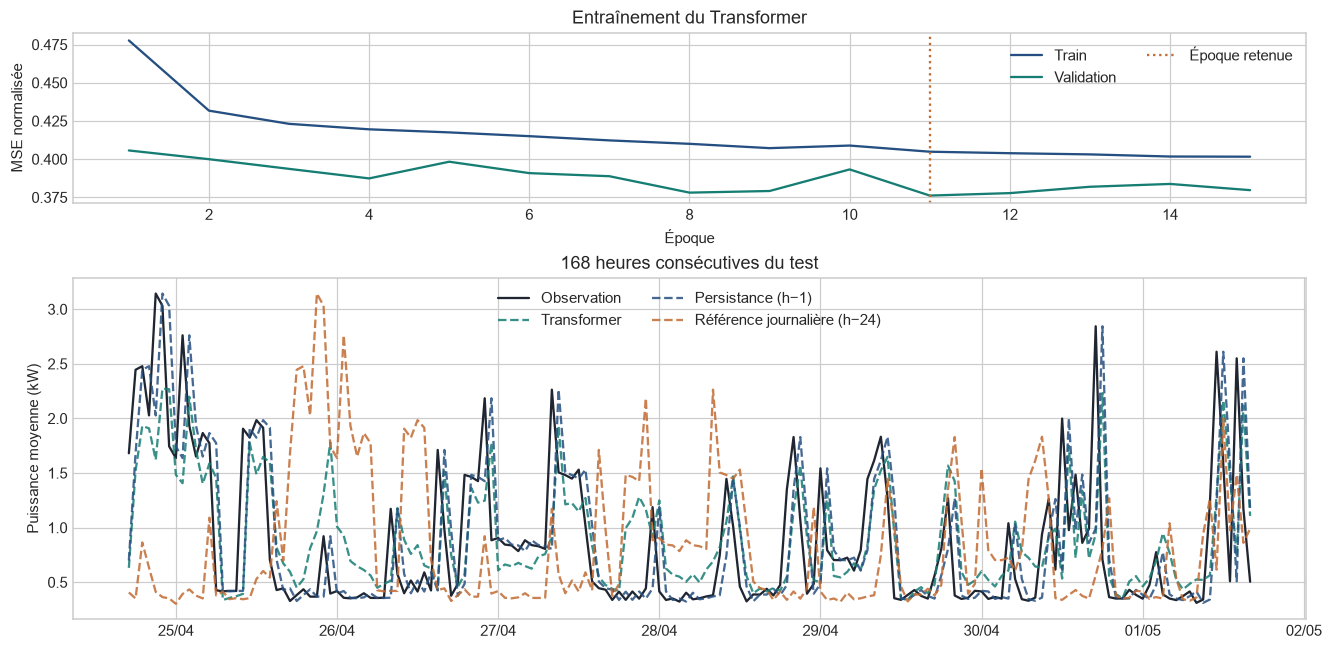

In [9]:
dates_test = serie_kw.index[i_kw[g_kw["test"]]]
heure_ns = pd.Timedelta(hours=1).value
ruptures = np.r_[0, np.flatnonzero(np.diff(dates_test.as_unit("ns").asi8) != heure_ns) + 1, len(dates_test)]
debut = next(a for a, b in zip(ruptures[:-1], ruptures[1:]) if b - a >= 168)
portion = slice(debut, debut + 168)
assert dates_test[portion][-1] - dates_test[portion][0] == pd.Timedelta(hours=167)

fig, axes = plt.subplots(2, 1, figsize=(12, 5.8), height_ratios=[1, 2], layout="constrained")
for nom, couleur in zip(hist_kw, [BLEU, VERT]):
    axes[0].plot(hist_kw.index, hist_kw[nom], color=couleur, label=nom)
axes[0].axvline(epoque_kw, color=ORANGE, linestyle=":", label="Époque retenue")
axes[0].set(xlabel="Époque", ylabel="MSE normalisée", title="Entraînement du Transformer")
axes[1].plot(dates_test[portion], vrai_kw[portion], color="#202631", label="Observation")
for (nom, pred), couleur in zip(pred_kw.items(), [VERT, BLEU, ORANGE]):
    axes[1].plot(dates_test[portion], pred[portion], "--", alpha=0.85, color=couleur, label=nom)
axes[1].set(ylabel="Puissance moyenne (kW)", title="168 heures consécutives du test")
axes[1].xaxis.set_major_locator(mdates.DayLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
for ax in axes:
    ax.legend(ncol=2)
plt.show()

#### Discussion

1. **Comparaison aux références.** Le tableau et le bilan ci-dessus comparent le Transformer à chaque référence, sur les mêmes cibles et pour chacune des deux métriques. Chaque point utilise les 24 mesures réellement disponibles avant l’heure cible.
2. **Une fenêtre de 168 heures** donnerait accès à la même heure de la semaine précédente. L’effet reste à mesurer, car les fenêtres complètes seraient moins nombreuses et le calcul d’attention plus coûteux. Une comparaison équitable utiliserait les mêmes cibles de test.
3. **L’heure et le jour** permettent de représenter les cycles quotidiens et hebdomadaires. On peut encoder chacun avec un couple sinus/cosinus pour que minuit soit proche de 23 h et lundi de dimanche.
4. **La normalisation sur le train** évite que la distribution des mesures de validation ou de test influence l’entraînement.
5. **Pour prédire une énergie en kWh**, intégrer la puissance sur l’heure : pour 60 mesures d’une minute supposées représentatives de leur minute, sommer les valeurs en kW multipliées par 1/60 h. Une heure incomplète demande une estimation explicite des minutes manquantes ou son exclusion.

### Exercice 2 · Mini-GPT à caractères

Le fichier `corpus.txt` contient un carnet d’observation original. Le dernier segment sert à la validation. Chaque entrée de 64 caractères a une cible décalée d’un caractère, de sorte que la perte entraîne les 64 prédictions. Les deux blocs de dimension 64 comportent chacun quatre têtes, deux pré-normalisations, deux connexions résiduelles et un MLP 64 → 256 → 64 avec GELU.

In [10]:
texte = Path("corpus.txt").read_text(encoding="utf-8")
coupure = texte.rfind("\n\n", 0, int(0.87 * len(texte)))
texte_train, texte_val = texte[:coupure], texte[coupure:].strip()
caracteres = sorted(set(texte_train))
stoi = {caractere: i for i, caractere in enumerate(caracteres)}
caracteres_hors_vocabulaire = sorted(set(texte_val) - set(stoi))
assert not caracteres_hors_vocabulaire, caracteres_hors_vocabulaire
tokens_train = torch.tensor([stoi[c] for c in texte_train])
tokens_val = torch.tensor([stoi[c] for c in texte_val])
CONTEXTE = 64

def lot_caracteres(tokens, nombre, generateur):
    debuts = torch.randint(len(tokens) - CONTEXTE, (nombre,), generator=generateur)
    indices = debuts[:, None] + torch.arange(CONTEXTE + 1)
    blocs = tokens[indices].to(device)
    return blocs[:, :-1], blocs[:, 1:]

print(f"{len(tokens_train):,} caractères train · {len(tokens_val):,} validation · {len(stoi)} symboles")
print("Entrée :", repr(texte_train[:CONTEXTE]))
print("Cible  :", repr(texte_train[1:CONTEXTE + 1]))

6,068 caractères train · 1,008 validation · 54 symboles
Entrée : 'Le ciel au-dessus des cèdres\n\nDepuis le chemin de pierre, la cou'
Cible  : 'e ciel au-dessus des cèdres\n\nDepuis le chemin de pierre, la coup'


In [11]:
class BlocGPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.norm_attention = nn.LayerNorm(64)
        self.attention = nn.MultiheadAttention(64, 4, batch_first=True)
        self.norm_mlp = nn.LayerNorm(64)
        self.mlp = nn.Sequential(nn.Linear(64, 256), nn.GELU(), nn.Linear(256, 64))

    def forward(self, x, masque):
        z = self.norm_attention(x)
        attention, _ = self.attention(z, z, z, attn_mask=masque, need_weights=False)
        x = x + attention
        return x + self.mlp(self.norm_mlp(x))


class MiniGPT(nn.Module):
    def __init__(self, vocabulaire):
        super().__init__()
        self.tokens = nn.Embedding(vocabulaire, 64)
        self.positions = nn.Embedding(CONTEXTE, 64)
        self.blocs = nn.ModuleList([BlocGPT(), BlocGPT()])
        self.sortie = nn.Sequential(nn.LayerNorm(64), nn.Linear(64, vocabulaire))
        self.register_buffer("causal", torch.ones(CONTEXTE, CONTEXTE, dtype=torch.bool).triu(1))

    def forward(self, ids):
        longueur = ids.size(1)
        x = self.tokens(ids) + self.positions(torch.arange(longueur, device=ids.device))
        for bloc in self.blocs:
            x = bloc(x, self.causal[:longueur, :longueur])
        return self.sortie(x)


def perte_langage(logits, cibles):
    return F.cross_entropy(logits.flatten(0, 1), cibles.flatten(), ignore_index=-100)


@torch.inference_mode()
def controler_causalite(modele, ids):
    modele.eval()
    modifies = ids.clone()
    modifies[:, 40] = (modifies[:, 40] + 1) % len(stoi)
    torch.testing.assert_close(modele(ids)[:, :40], modele(modifies)[:, :40], atol=1e-5, rtol=1e-5)

Causalité vérifiée · pas retenu 500 · perte validation 2.091


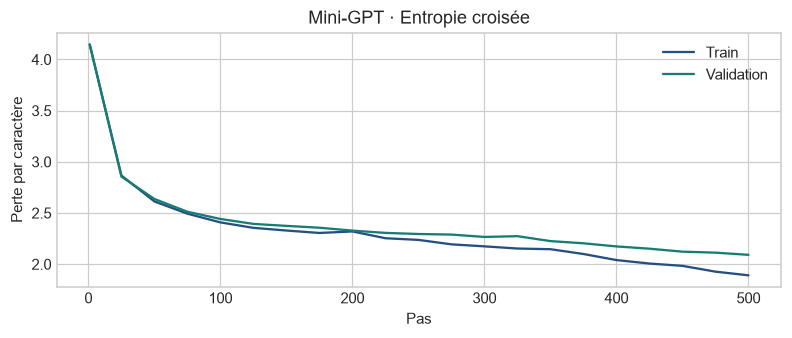

In [12]:
torch.manual_seed(GRAINE)
mini_gpt = MiniGPT(len(stoi)).to(device)
opt_gpt = torch.optim.AdamW(mini_gpt.parameters(), lr=0.001)
rng_gpt = torch.Generator().manual_seed(GRAINE)
lots_val_gpt = [lot_caracteres(tokens_val, 24, rng_gpt) for _ in range(6)]
hist_gpt, min_gpt = [], float("inf")
for pas in range(1, 501):
    mini_gpt.train()
    x, y = lot_caracteres(tokens_train, 24, rng_gpt)
    opt_gpt.zero_grad(set_to_none=True)
    perte = perte_langage(mini_gpt(x), y)
    perte.backward()
    opt_gpt.step()
    if pas == 1 or pas % 25 == 0:
        mini_gpt.eval()
        with torch.inference_mode():
            train = torch.stack([
                perte_langage(mini_gpt(a), b)
                for a, b in (lot_caracteres(tokens_train, 24, rng_gpt) for _ in range(3))
            ]).mean().item()
            validation = torch.stack([
                perte_langage(mini_gpt(a), b) for a, b in lots_val_gpt
            ]).mean().item()
        hist_gpt.append((pas, train, validation))
        if validation < min_gpt:
            min_gpt, pas_gpt, poids_gpt = validation, pas, deepcopy(mini_gpt.state_dict())
mini_gpt.load_state_dict(poids_gpt)
controler_causalite(mini_gpt, lots_val_gpt[0][0][:2])
print(f"Causalité vérifiée · pas retenu {pas_gpt} · perte validation {min_gpt:.3f}")

suivi_gpt = pd.DataFrame(hist_gpt, columns=["Pas", "Train", "Validation"]).set_index("Pas")
ax = suivi_gpt.plot(figsize=(8.5, 3), color=[BLEU, VERT], title="Mini-GPT · Entropie croisée")
ax.set_ylabel("Perte par caractère")
plt.show()

In [13]:
@torch.inference_mode()
def generer_caracteres(modele, amorce, temperature, nombre=200):
    modele.eval()
    ids = torch.tensor([[stoi[c] for c in amorce]], device=device)
    rng = torch.Generator(device=device).manual_seed(GRAINE)
    ajouts = []
    for _ in range(nombre):
        logits = modele(ids[:, -CONTEXTE:])[0, -1]
        proba = (logits / temperature).softmax(-1)
        suivant = torch.multinomial(proba, 1, generator=rng)
        ids = torch.cat((ids, suivant.view(1, 1)), dim=1)
        ajouts.append(caracteres[suivant.item()])
    return "".join(ajouts)

amorce = "Le ciel"
continuations = {}
for temperature in [0.5, 1.0, 1.5]:
    suite = generer_caracteres(mini_gpt, amorce, temperature)
    assert len(suite) == 200
    continuations[temperature] = suite
    print(f"Température {temperature:.1f}\n{amorce}{suite}\n")

Température 0.5
Le ciel la mes le sent le les des sampes la des til de le de bres roit une de de de de des de de la cru qu de la de prre une de conde la de de la parve de de sorde le plasisire pe la corservire mare sur and 



Température 1.0
Le ciel la mes. Les. Un Lour les escha surallle til . Silles brêmer pes vert des e réféès illl lespharèvenns re rer durexut sil. Ens lillaraurerrepce vant de rore ser plixarnos pât quante charenmur bs urat l



Température 1.5
Le ciel lal quel parat, Léle sésceschamairllèle til..

Sanqé brês rope. vePt cis e réféèssierl lispharu quns rè mer nurexutr gle enxe vle raurerrepcrevantrell dre ser avix mmiont elquangzSens,'imurêbsge as l



#### Discussion

1. **Sans masque causal**, une position peut lire le caractère suivant dans l’entrée, sauf à l’extrémité de la fenêtre. La perte d’entraînement peut alors être artificiellement basse sans bénéficier à la génération.
2. **À 0,5**, la distribution favorise davantage les caractères les plus probables. **À 1,0**, on échantillonne dans la distribution brute. **À 1,5**, les choix moins probables deviennent plus fréquents. Le petit corpus limite la cohérence des textes obtenus.
3. **Le décalage des cibles** associe à chaque position le caractère à écrire ensuite. Sans décalage, la cible serait le caractère déjà visible à cette position.

Dans cette exécution, la continuation à 0,5 répète souvent des fragments courts comme « de de ». Celle à 1,5 contient davantage de suites de lettres atypiques et de changements de casse. Les trois sorties restent difficiles à lire, ce qui illustre les limites de cet entraînement sur un petit corpus.

### Exercice 3 · Mini-BERT à mots

Le corpus synthétique combine plusieurs scènes liées à l’observatoire. Les phrases de validation sont des combinaisons inédites. Le vocabulaire est construit sur l’entraînement. Les identifiants 0 à 4 sont réservés à `[PAD]`, `[UNK]`, `[CLS]`, `[SEP]` et `[MASK]`. Chaque phrase est encodée sur 32 positions.

On sélectionne chaque mot ordinaire avec une probabilité de 15 %, en imposant au moins une sélection par phrase. Parmi les positions sélectionnées, les probabilités sont 80 % pour `[MASK]`, 10 % pour un mot ordinaire aléatoire et 10 % pour le mot d’origine. Les autres cibles valent −100 et sont ignorées dans la perte.

In [14]:
scenes = [
    (["la photographe", "la guide", "la technicienne"], ["règle", "nettoie"],
     ["le télescope", "le trépied", "la caméra"], ["sous la coupole", "près de la fenêtre"]),
    (["le botaniste", "la jardinière", "le stagiaire"], ["observe", "arrose"],
     ["la fougère", "le cactus", "le lierre"], ["dans la serre", "sur la terrasse"]),
    (["le météorologue", "la chercheuse", "le doctorant"], ["vérifie", "installe"],
     ["le baromètre", "le capteur", "le thermomètre"], ["sur le toit", "dans la station"]),
    (["le bibliothécaire", "la documentaliste", "la conservatrice"], ["classe", "consulte"],
     ["le registre", "la carte", "le carnet"], ["dans les archives", "à la bibliothèque"]),
]
moments = ["avant le dîner", "après le déjeuner", "au lever du jour", "en fin de soirée"]
rng_corpus = np.random.default_rng(GRAINE)
phrases_train, phrases_val = [], []
for sujets, verbes, objets, lieux in scenes:
    phrases = [" ".join(p) for p in itertools.product(sujets, verbes, objets, lieux, moments)]
    ordre = rng_corpus.permutation(len(phrases))
    phrases_train.extend(phrases[i] for i in ordre[28:])
    phrases_val.extend(phrases[i] for i in ordre[:28])
assert not set(phrases_train) & set(phrases_val)

PAD, UNK, CLS, SEP, MASK = range(5)
speciaux = ["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"]
mots = speciaux + sorted({mot for phrase in phrases_train for mot in phrase.split()})
indices_mots = {mot: i for i, mot in enumerate(mots)}
MAX_MOTS = 32

def encoder_phrase(phrase):
    ids = [indices_mots.get(mot, UNK) for mot in phrase.split()][:MAX_MOTS - 2]
    return [CLS, *ids, SEP] + [PAD] * (MAX_MOTS - len(ids) - 2)

ids_train = torch.tensor([encoder_phrase(phrase) for phrase in phrases_train])
ids_val = torch.tensor([encoder_phrase(phrase) for phrase in phrases_val])

def masquer(ids, rng):
    ordinaires = ids >= len(speciaux)
    selection = (torch.rand(ids.shape, generator=rng) < 0.15) & ordinaires
    lignes = torch.where(~selection.any(dim=1) & ordinaires.any(dim=1))[0]
    if lignes.numel():
        positions = torch.multinomial(ordinaires[lignes].float(), 1, generator=rng)
        selection[lignes, positions.squeeze(1)] = True
    etiquette = ids.masked_fill(~selection, -100)
    tirage = torch.rand(ids.shape, generator=rng)
    corrompus = ids.masked_fill(selection & (tirage < 0.8), MASK)
    aleatoires = selection & (tirage >= 0.8) & (tirage < 0.9)
    corrompus[aleatoires] = torch.randint(len(speciaux), len(mots),
                                         (int(aleatoires.sum()),), generator=rng)
    return corrompus, etiquette

print(f"{len(ids_train)} phrases train · {len(ids_val)} validation · {len(mots)} entrées de vocabulaire")
exemple, cible = masquer(ids_train[:1], torch.Generator().manual_seed(GRAINE))
print("Phrase corrompue :", " ".join(mots[i] for i in exemple[0].tolist() if i != PAD))
print("Mots sélectionnés :", [mots[i] for i in cible[0].tolist() if i != -100])

464 phrases train · 112 validation · 65 entrées de vocabulaire
Phrase corrompue : [CLS] [MASK] technicienne règle le télescope sous la [MASK] après le déjeuner [SEP]
Mots sélectionnés : ['la', 'coupole']


In [15]:
class MiniBERT(nn.Module):
    def __init__(self, vocabulaire):
        super().__init__()
        self.mots = nn.Embedding(vocabulaire, 64, padding_idx=PAD)
        self.positions = nn.Embedding(MAX_MOTS, 64)
        couche = nn.TransformerEncoderLayer(64, 4, 256, dropout=0.1,
                                           activation="gelu", batch_first=True)
        self.encodeur = nn.TransformerEncoder(couche, 2, enable_nested_tensor=False)
        self.sortie = nn.Linear(64, vocabulaire)

    def forward(self, ids, padding):
        positions = torch.arange(ids.size(1), device=ids.device)
        x = self.mots(ids) + self.positions(positions)
        return self.sortie(self.encodeur(x, src_key_padding_mask=padding))


@torch.inference_mode()
def mesurer_mlm(modele, ids, corrompus, etiquette):
    modele.eval()
    logits = modele(corrompus.to(device), (ids == PAD).to(device))
    cibles = etiquette.to(device)
    selection = cibles != -100
    exactitude = (logits.argmax(-1)[selection] == cibles[selection]).float().mean().item()
    return perte_langage(logits, cibles).item(), exactitude


@torch.inference_mode()
def controler_padding(modele, ids):
    modele.eval()
    padding = ids == PAD
    assert padding.any() and (~padding).any()
    modifies = ids.masked_fill(padding, MASK)
    torch.testing.assert_close(modele(ids, padding)[~padding],
                               modele(modifies, padding)[~padding], atol=1e-5, rtol=1e-5)

Padding vérifié · époque retenue 35
Validation · 198 positions sélectionnées · exactitude 89.4% · perte 0.246


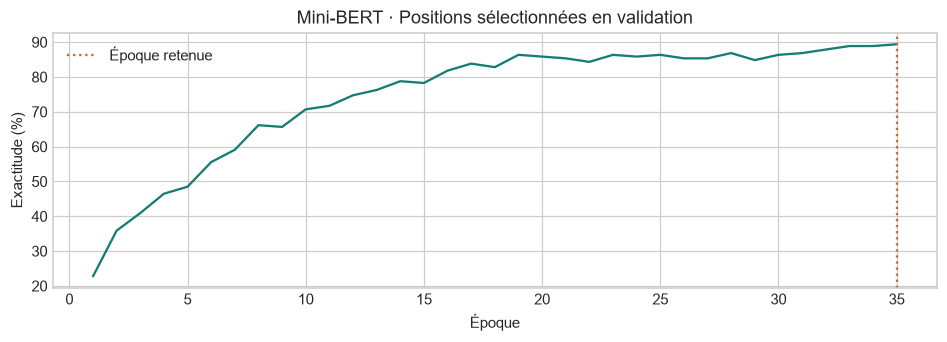

In [16]:
torch.manual_seed(GRAINE)
mini_bert = MiniBERT(len(mots)).to(device)
opt_bert = torch.optim.AdamW(mini_bert.parameters(), lr=0.001)
rng_bert = torch.Generator().manual_seed(GRAINE + 1)
val_entree, val_cible = masquer(ids_val, torch.Generator().manual_seed(GRAINE + 2))
assert (val_cible != -100).any(dim=1).all()
hist_bert, min_bert = [], float("inf")
for epoque in range(1, 36):
    mini_bert.train()
    for indices in torch.randperm(len(ids_train), generator=rng_bert).split(48):
        ids = ids_train[indices]
        entree, cible = masquer(ids, rng_bert)
        opt_bert.zero_grad(set_to_none=True)
        logits = mini_bert(entree.to(device), (ids == PAD).to(device))
        perte = perte_langage(logits, cible.to(device))
        perte.backward()
        opt_bert.step()
    perte_val, exactitude = mesurer_mlm(mini_bert, ids_val, val_entree, val_cible)
    hist_bert.append((epoque, perte_val, exactitude))
    if perte_val < min_bert:
        min_bert, epoque_bert, poids_bert = perte_val, epoque, deepcopy(mini_bert.state_dict())
mini_bert.load_state_dict(poids_bert)
controler_padding(mini_bert, ids_val[:3].to(device))
perte_val, exactitude = mesurer_mlm(mini_bert, ids_val, val_entree, val_cible)
print(f"Padding vérifié · époque retenue {epoque_bert}")
print(f"Validation · {int((val_cible != -100).sum())} positions sélectionnées · "
      f"exactitude {exactitude:.1%} · perte {perte_val:.3f}")

fig, ax = plt.subplots(figsize=(8.5, 3), layout="constrained")
suivi_bert = pd.DataFrame(hist_bert, columns=["Époque", "Perte", "Exactitude"])
ax.plot(suivi_bert["Époque"], suivi_bert["Exactitude"] * 100, color=VERT)
ax.axvline(epoque_bert, linestyle=":", color=ORANGE, label="Époque retenue")
ax.set(xlabel="Époque", ylabel="Exactitude (%)", title="Mini-BERT · Positions sélectionnées en validation")
ax.legend()
plt.show()

In [17]:
@torch.inference_mode()
def proposer_mots(phrase, position):
    mini_bert.eval()
    ids = torch.tensor([encoder_phrase(phrase)], device=device)
    attendu = mots[ids[0, position + 1].item()]
    ids[0, position + 1] = MASK
    proba = mini_bert(ids, ids == PAD)[0, position + 1].softmax(-1)
    valeurs, indices = proba[len(speciaux):].topk(3)
    phrase_masquee = phrase.split()
    phrase_masquee[position] = "[MASK]"
    candidats = [f"{mots[i + len(speciaux)]} ({p:.1%})" for i, p in zip(indices.tolist(), valeurs.tolist())]
    print(f"{' '.join(phrase_masquee)}\nAttendu : {attendu} · Top 3 : {', '.join(candidats)}\n")

for indice, position in [(0, 1), (30, 2), (60, 4), (90, 1)]:
    proposer_mots(phrases_val[indice], position)

la [MASK] règle le télescope près de la fenêtre avant le dîner
Attendu : photographe · Top 3 : technicienne (37.7%), photographe (36.7%), guide (19.4%)

le stagiaire [MASK] la fougère sur la terrasse au lever du jour
Attendu : observe · Top 3 : arrose (52.7%), observe (43.9%), installe (0.5%)

la chercheuse vérifie le [MASK] dans la station avant le dîner
Attendu : baromètre · Top 3 : baromètre (52.2%), thermomètre (21.4%), capteur (18.3%)

la [MASK] consulte le carnet dans les archives avant le dîner
Attendu : documentaliste · Top 3 : documentaliste (50.5%), conservatrice (41.9%), bibliothécaire (3.3%)



#### Discussion

1. **Le contexte droit est accessible** parce que l’auto-attention utilise un masque de padding et autorise toutes les relations entre positions utiles.
2. **La perte cible les positions sélectionnées** pour concentrer l’apprentissage sur la reconstruction. Une position sélectionnée reste une cible même si l’entrée conserve le mot original. L’exactitude mesurée mélange les trois types de corruption.
3. **L’entraînement reconstruit une position dans une phrase**. Il ne définit pas la prédiction du prochain token à partir d’un préfixe comme le fait le mini-GPT. Plusieurs complétions peuvent convenir aux phrases synthétiques.

### Références

- Support *Architecture Transformers*, Pr Mohamed Youssfi, et énoncés regroupés dans `architecture_transformer-2.ipynb`.
- Hebrail, G. et Berard, A. (2006), *Individual Household Electric Power Consumption*, UCI Machine Learning Repository. Jeu d’origine inclus sous licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). [DOI 10.24432/C58K54](https://doi.org/10.24432/C58K54).
- Modèles préentraînés : [DistilGPT2](https://huggingface.co/distilbert/distilgpt2) et [BERT base uncased](https://huggingface.co/google-bert/bert-base-uncased).